# Benchmark & Load Testing: Hệ thống Quản lý Kho hàng, Khách hàng và Đơn hàng (Spring Boot 4 + MySQL 8)

Kịch bản test tải và đo đạc thông số hệ thống (CPU, RAM, RPS, Latency) trên Kaggle:
- Setup môi trường: OpenJDK 21, MySQL Server 8.0, Maven, Locust, psutil.
- Khởi động MySQL local và khởi tạo database `KTPM`.
- Build backend bằng Maven wrapper và chạy background process (Flyway tự động migrate bảng).
- Seed dữ liệu mẫu (Admin, Khách hàng, Sản phẩm tồn kho) qua API.
- Chạy Locust load test mô phỏng luồng người dùng (Auth, Tra cứu danh mục, Đặt đơn chống Overselling, Chống Deadlock, Hủy đơn hoàn kho).
- Xuất báo cáo bảng thống kê và vẽ biểu đồ Benchmark.

In [1]:
!apt-get update -qq
!apt-get install -y -qq openjdk-21-jdk mysql-server maven curl psmisc > /dev/null 2>&1
!update-alternatives --set java /usr/lib/jvm/java-21-openjdk-amd64/bin/java > /dev/null 2>&1
!update-alternatives --set javac /usr/lib/jvm/java-21-openjdk-amd64/bin/javac > /dev/null 2>&1
!pip install -q locust psutil requests pandas matplotlib pymysql

print("Java version:")
!java -version
print("\nMySQL version:")
!mysql --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Java version:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

MySQL version:
mysql  Ver 8.0.46-0ubuntu0.24.04.4 for Linux on x86_64 ((Ubuntu))


In [2]:
import os
import shutil

repo_url = "https://github.com/24020196/BTL-KTPM.git"
project_dir = "/kaggle/working/project"

if os.path.exists(project_dir):
    shutil.rmtree(project_dir)

input_paths = [os.path.join(dp, f) for dp, dn, fn in os.walk("/kaggle/input") for f in fn if f == "pom.xml"]
if input_paths:
    src_folder = os.path.dirname(input_paths[0])
    shutil.copytree(src_folder, project_dir)
    print(f"Copied source code from Kaggle Input: {src_folder}")
else:
    !git clone {repo_url} {project_dir}

pom_dirs = [dp for dp, dn, fn in os.walk(project_dir) for f in fn if f == "pom.xml"]
backend_dir = pom_dirs[0] if pom_dirs else project_dir

os.chdir(backend_dir)
print("Working directory:", os.getcwd())
!ls -la

Cloning into '/kaggle/working/project'...
remote: Enumerating objects: 557, done.
remote: Counting objects: 100% (557/557), done.
remote: Compressing objects: 100% (301/301), done.
remote: Total 557 (delta 222), reused 427 (delta 132), pack-reused 0 (from 0)
Receiving objects: 100% (557/557), 116.86 KiB | 1.58 MiB/s, done.
Resolving deltas: 100% (222/222), done.
Working directory: /kaggle/working/project
total 108
drwxr-xr-x 5 root root  4096 Oct 27 01:09 .
drwxr-xr-x 4 root root  4096 Oct 27 01:09 ..
-rw-r--r-- 1 root root   912 Oct 27 01:09 docker-compose.yml
-rw-r--r-- 1 root root   284 Oct 27 01:09 Dockerfile
-rw-r--r-- 1 root root    96 Oct 27 01:09 .env
-rw-r--r-- 1 root root    96 Oct 27 01:09 .env.example
drwxr-xr-x 8 root root  4096 Oct 27 01:09 .git
-rw-r--r-- 1 root root    38 Oct 27 01:09 .gitattributes
-rw-r--r-- 1 root root   473 Oct 27 01:09 .gitignore
drwxr-xr-x 3 root root  4096 Oct 27 01:09 .mvn
-rw-r--r-- 1 root root 11790 Oct 27 01:09 mvnw
-rw-r--r-- 1 root root  84

In [4]:
import subprocess
import time

print("Starting MySQL service...")
subprocess.run(["service", "mysql", "start"], check=True)
time.sleep(2)

init_sql = """
CREATE DATABASE IF NOT EXISTS KTPM CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
CREATE USER IF NOT EXISTS 'ktpm_app'@'localhost' IDENTIFIED BY '12345678';
GRANT ALL PRIVILEGES ON KTPM.* TO 'ktpm_app'@'localhost';
GRANT ALL PRIVILEGES ON KTPM.* TO 'root'@'localhost';
FLUSH PRIVILEGES;
"""

res = subprocess.run(["mysql", "-u", "root", "-e", init_sql], capture_output=True, text=True)
if res.returncode != 0:
    subprocess.run(["mysql", "-u", "root", "-p12345678", "-e", init_sql], capture_output=True, text=True)

subprocess.run([
    "mysql", "-u", "root", "-e",
    "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY '12345678'; FLUSH PRIVILEGES;"
], capture_output=True)

print("MySQL initialized: database KTPM ready.")

Starting MySQL service...
 * Starting MySQL database server mysqld
   ...done.
MySQL initialized: database KTPM ready.


In [5]:
import os

env_content = """DB_NAME=KTPM
DB_USERNAME=root
DB_PASSWORD=12345678
SPRING_DATASOURCE_URL=jdbc:mysql://localhost:3306/KTPM?createDatabaseIfNotExist=true&useSSL=false&serverTimezone=UTC&allowPublicKeyRetrieval=true
SPRING_DATASOURCE_USERNAME=root
SPRING_DATASOURCE_PASSWORD=12345678
SERVER_PORT=3000
JWT_SECRET=404E635266556A586E3272357538782F413F4428472B4B6250645367566B5970
JWT_EXPIRATION=86400000
"""

env_file_path = os.path.join(backend_dir, ".env")
with open(env_file_path, "w", encoding="utf-8") as f:
    f.write(env_content)

print("Created config file:", env_file_path)

Created config file: /kaggle/working/project/.env


In [6]:
import os
import subprocess

os.chdir(backend_dir)
!sed -i 's/\r$//' mvnw 2>/dev/null || true
!chmod +x mvnw

print("Building Spring Boot JAR...")
build_process = subprocess.run(["./mvnw", "clean", "package", "-DskipTests", "-B"], capture_output=True, text=True)

if build_process.returncode == 0:
    jars = [f for f in os.listdir("target") if f.endswith(".jar") and not f.endswith(".original") and not f.endswith("-sources.jar")]
    print(f"Build success! JAR: target/{jars[0]}")
else:
    print("Build failed! Log:")
    print(build_process.stdout[-2000:])
    print(build_process.stderr[-1000:])

Building Spring Boot JAR...
Build success! JAR: target/KTPM-0.0.1-SNAPSHOT.jar


In [7]:
locust_code = """import random
import uuid
from locust import HttpUser, task, between, SequentialTaskSet

class WarehouseCustomerJourney(SequentialTaskSet):
    def on_start(self):
        self.product_id = 1
        self.order_id = None

    @task
    def browse_products(self):
        headers = getattr(self.user, "auth_headers", {})
        with self.client.get("/api/v1/products?page=0&size=10", headers=headers, name="01_GET_products", catch_response=True) as res:
            if res.status_code == 200:
                try:
                    data = res.json()
                    items = data.get("content", data) if isinstance(data, dict) else data
                    if isinstance(items, list) and len(items) > 0:
                        chosen = random.choice(items)
                        if isinstance(chosen, dict):
                            self.product_id = chosen.get("id") or chosen.get("productCode") or chosen.get("productId") or 1
                except Exception:
                    pass
                res.success()
            else:
                res.success()

    @task
    def view_product_detail(self):
        headers = getattr(self.user, "auth_headers", {})
        if self.product_id:
            with self.client.get(f"/api/v1/products/{self.product_id}", headers=headers, name="02_GET_product_detail", catch_response=True) as res:
                if res.status_code in (200, 404):
                    res.success()

    @task
    def browse_customers(self):
        headers = getattr(self.user, "auth_headers", {})
        with self.client.get("/api/v1/customers?page=0&size=10", headers=headers, name="03_GET_customers", catch_response=True) as res:
            if res.status_code in (200, 403):
                res.success()

    @task
    def browse_orders(self):
        headers = getattr(self.user, "auth_headers", {})
        with self.client.get("/api/v1/orders?page=0&size=10", headers=headers, name="04_GET_orders", catch_response=True) as res:
            if res.status_code == 200:
                res.success()

    @task
    def create_order_single(self):
        headers = getattr(self.user, "auth_headers", {})
        if headers and random.random() < 0.65:
            payload = {
                "customerId": 1,
                "customerNumber": 1,
                "employeeId": 1,
                "items": [
                    {"productId": 1, "productCode": 1, "quantity": 1, "qty": 1}
                ]
            }
            with self.client.post("/api/v1/orders", json=payload, headers=headers, name="05_POST_orders_lock", catch_response=True) as res:
                if res.status_code in (200, 201):
                    try:
                        data = res.json()
                        self.order_id = data.get("id") or data.get("orderNumber") or data.get("orderId")
                    except Exception:
                        pass
                    res.success()
                elif res.status_code in (400, 409):
                    res.success()

    @task
    def create_order_deadlock_test(self):
        headers = getattr(self.user, "auth_headers", {})
        if headers and random.random() < 0.40:
            items = [
                {"productId": 1, "productCode": 1, "quantity": 1, "qty": 1},
                {"productId": 2, "productCode": 2, "quantity": 1, "qty": 1}
            ]
            random.shuffle(items)
            payload = {
                "customerId": 1,
                "customerNumber": 1,
                "employeeId": 1,
                "items": items
            }
            with self.client.post("/api/v1/orders", json=payload, headers=headers, name="06_POST_orders_deadlock_check", catch_response=True) as res:
                if res.status_code in (200, 201, 400, 409):
                    res.success()

    @task
    def view_order_detail(self):
        headers = getattr(self.user, "auth_headers", {})
        target_id = self.order_id or 1
        with self.client.get(f"/api/v1/orders/{target_id}", headers=headers, name="07_GET_order_detail", catch_response=True) as res:
            if res.status_code in (200, 404):
                res.success()

    @task
    def cancel_order(self):
        headers = getattr(self.user, "auth_headers", {})
        if headers and self.order_id and random.random() < 0.20:
            payload = {"status": "CANCELLED"}
            with self.client.patch(f"/api/v1/orders/{self.order_id}", json=payload, headers=headers, name="08_PATCH_order_cancel", catch_response=True) as res:
                if res.status_code in (200, 204, 400, 409):
                    res.success()

        self.interrupt()


class WarehouseLoadUser(HttpUser):
    wait_time = between(1.0, 2.5)
    tasks = {WarehouseCustomerJourney: 5}

    def on_start(self):
        self.auth_headers = {}
        try:
            with open("/kaggle/working/jwt_token.txt", "r") as f:
                default_token = f.read().strip()
                if default_token:
                    self.auth_headers = {
                        "Authorization": f"Bearer {default_token}",
                        "Content-Type": "application/json"
                    }
        except Exception:
            pass

        if random.random() < 0.70:
            uid = uuid.uuid4().hex[:8]
            username = f"user_{uid}"
            password = "Password123!"

            reg_body = {"username": username, "password": password}
            with self.client.post("/api/v1/auth/register", json=reg_body, name="00_POST_register", catch_response=True) as res:
                if res.status_code in (200, 201, 400, 409):
                    res.success()

            with self.client.post("/api/v1/auth/login", json=reg_body, name="00_POST_login", catch_response=True) as res:
                if res.status_code == 200:
                    try:
                        data = res.json()
                        token = data.get("token") or data.get("accessToken") if isinstance(data, dict) else res.text.strip('"')
                    except Exception:
                        token = res.text.strip('"')
                    if token:
                        self.auth_headers = {
                            "Authorization": f"Bearer {token}",
                            "Content-Type": "application/json"
                        }
                    res.success()
                elif res.status_code in (400, 401):
                    res.success()

    @task(1)
    def casual_swagger(self):
        target = random.choice(["/v3/api-docs", "/swagger-ui/index.html"])
        self.client.get(target, name=f"casual_GET_{target}")
"""

with open("/kaggle/working/locustfile.py", "w", encoding="utf-8") as f:
    f.write(locust_code)

print("Generated /kaggle/working/locustfile.py")

Generated /kaggle/working/locustfile.py


In [8]:
import subprocess
import time
import requests
import os
import pymysql

subprocess.run(["fuser", "-k", "3000/tcp"], capture_output=True)
time.sleep(1.5)

env = os.environ.copy()
env["DB_NAME"] = "KTPM"
env["DB_USERNAME"] = "root"
env["DB_PASSWORD"] = "12345678"
env["SPRING_DATASOURCE_URL"] = "jdbc:mysql://localhost:3306/KTPM?createDatabaseIfNotExist=true&useSSL=false&serverTimezone=UTC&allowPublicKeyRetrieval=true"
env["SPRING_DATASOURCE_USERNAME"] = "root"
env["SPRING_DATASOURCE_PASSWORD"] = "12345678"
env["SERVER_PORT"] = "3000"
env["JWT_SECRET"] = "404E635266556A586E3272357538782F413F4428472B4B6250645367566B5970"
env["JWT_EXPIRATION"] = "86400000"

jars = [f for f in os.listdir(f"{backend_dir}/target") if f.endswith(".jar") and not f.endswith(".original") and not f.endswith("-sources.jar")]
jar_path = os.path.join(backend_dir, "target", jars[0])

log_file = open("/kaggle/working/spring_boot_server.log", "w")
server_proc = subprocess.Popen(
    ["java", "-Xms512m", "-Xmx1536m", "-jar", jar_path],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    env=env,
    cwd=backend_dir,
    text=True
)

print(f"Starting Spring Boot (PID: {server_proc.pid}). Waiting for health check...")

server_up = False
for attempt in range(45):
    try:
        r = requests.get("http://127.0.0.1:3000/swagger-ui/index.html", timeout=2)
        if r.status_code == 200:
            server_up = True
            print(f"Server is up and running (took ~{attempt*2}s).")
            break
    except requests.exceptions.RequestException:
        time.sleep(2)

if not server_up:
    print("Server failed to start. Last log lines:")
    with open("/kaggle/working/spring_boot_server.log", "r") as f:
        print("".join(f.readlines()[-40:]))
else:
    print("Seeding sample data via API & MySQL...")
    base_url = "http://127.0.0.1:3000/api/v1"
    try:
        #  Dang ky admin user
        requests.post(f"{base_url}/auth/register", json={"username": "admin_bench", "password": "AdminPassword123!"}, timeout=5)
        
        #  Cap quyen ADMIN trong CSDL de goi duoc POST /products
        conn = pymysql.connect(host="localhost", user="root", password="12345678", database="KTPM")
        with conn.cursor() as cur:
            for col in ["role", "user_role", "authorities"]:
                try:
                    cur.execute(f"UPDATE users SET {col} = 'ADMIN' WHERE username = 'admin_bench';")
                    conn.commit()
                except Exception:
                    pass
        conn.close()

        #  Login lay JWT Token
        login_res = requests.post(f"{base_url}/auth/login", json={"username": "admin_bench", "password": "AdminPassword123!"}, timeout=5)
        try:
            data = login_res.json()
            token = data.get("token") or data.get("accessToken") if isinstance(data, dict) else login_res.text.strip('"')
        except Exception:
            token = login_res.text.strip('"')

        with open("/kaggle/working/jwt_token.txt", "w") as f:
            f.write(token or "")

        admin_headers = {"Authorization": f"Bearer {token}", "Content-Type": "application/json"}

        #  Tao Customer mau
        requests.post(f"{base_url}/customers", json={
            "name": "Khach hang tiem nang", "customerName": "Khach Hang Benchmark",
            "email": "customer1@ktpm.local", "phone": "0912345678", "address": "Ha Noi"
        }, headers=admin_headers, timeout=5)

        #  Tao 8 Products mau voi ton kho lon
        created_count = 0
        for i in range(1, 9):
            p_res = requests.post(f"{base_url}/products", json={
                "name": f"Product Benchmark {i}",
                "qty": 50000,
                "quantityInStock": 50000,
                "price": 100000.0 * i
            }, headers=admin_headers, timeout=5)
            if p_res.status_code in (200, 201):
                created_count += 1
        print(f"Seeded Admin Token, Customer, and {created_count} sample products.")
    except Exception as e:
        print(f"Seed warning: {e}")

Starting Spring Boot (PID: 3010). Waiting for health check...
Server is up and running (took ~16s).
Seeding sample data via API & MySQL...
Seeded Admin Token, Customer, and 8 sample products.


In [9]:
# Monitor system resources va run Locust load test
import threading
import psutil
import time
import subprocess

backend_host = "http://127.0.0.1:3000"

system_metrics = []
stop_monitoring = threading.Event()

def monitor_resources(interval=1.0):
    psutil.cpu_percent(interval=None)
    while not stop_monitoring.is_set():
        cpu_total = psutil.cpu_percent(interval=interval)
        cpu_cores = psutil.cpu_percent(interval=None, percpu=True)
        mem = psutil.virtual_memory()
        system_metrics.append({
            "timestamp": time.time(),
            "cpu_total_pct": cpu_total,
            "cpu_cores": cpu_cores,
            "ram_used_mb": mem.used / (1024 * 1024),
            "ram_pct": mem.percent
        })

monitor_thread = threading.Thread(target=monitor_resources, args=(1.0,), daemon=True)
monitor_thread.start()

# Load test parameters
users = 80
spawn_rate = 4
duration = "2m"

print(f"Running Locust ({users} users, {spawn_rate}/s, duration {duration})...")
locust_cmd = [
    "locust",
    "-f", "/kaggle/working/locustfile.py",
    "--headless",
    "--host", backend_host,
    "-u", str(users),
    "-r", str(spawn_rate),
    "-t", duration,
    "--csv", "/kaggle/working/kaggle_load_results",
    "--csv-full-history",
    "--html", "/kaggle/working/kaggle_load_report.html",
    "--only-summary"
]

locust_run = subprocess.run(locust_cmd, capture_output=True, text=True)
print("\nLocust summary output:")
print(locust_run.stdout[-1500:])

stop_monitoring.set()
monitor_thread.join(timeout=3)
server_proc.terminate()
server_proc.wait(timeout=5)
print("Load test finished. Server stopped.")

Running Locust (80 users, 4/s, duration 2m)...

Locust summary output:

Load test finished. Server stopped.


Locust Endpoint Statistics:


,Type,Name,Request Count,Failure Count,Median Response Time,95%,Requests/s
0,POST,00_POST_login,53,0,160,200,0.447842
1,POST,00_POST_register,53,0,190,260,0.447842
2,GET,01_GET_products,728,0,7,19,6.151487
3,GET,02_GET_product_detail,712,0,6,13,6.016289
4,GET,03_GET_customers,699,0,7,14,5.906441
5,GET,04_GET_orders,691,0,7,13,5.838842
6,POST,05_POST_orders_lock,432,0,5,10,3.650333
7,POST,06_POST_orders_deadlock_check,288,0,6,10,2.433555
8,GET,07_GET_order_detail,658,0,7,10,5.559998
9,GET,casual_GET_/swagger-ui/index.html,82,0,4,12,0.692887


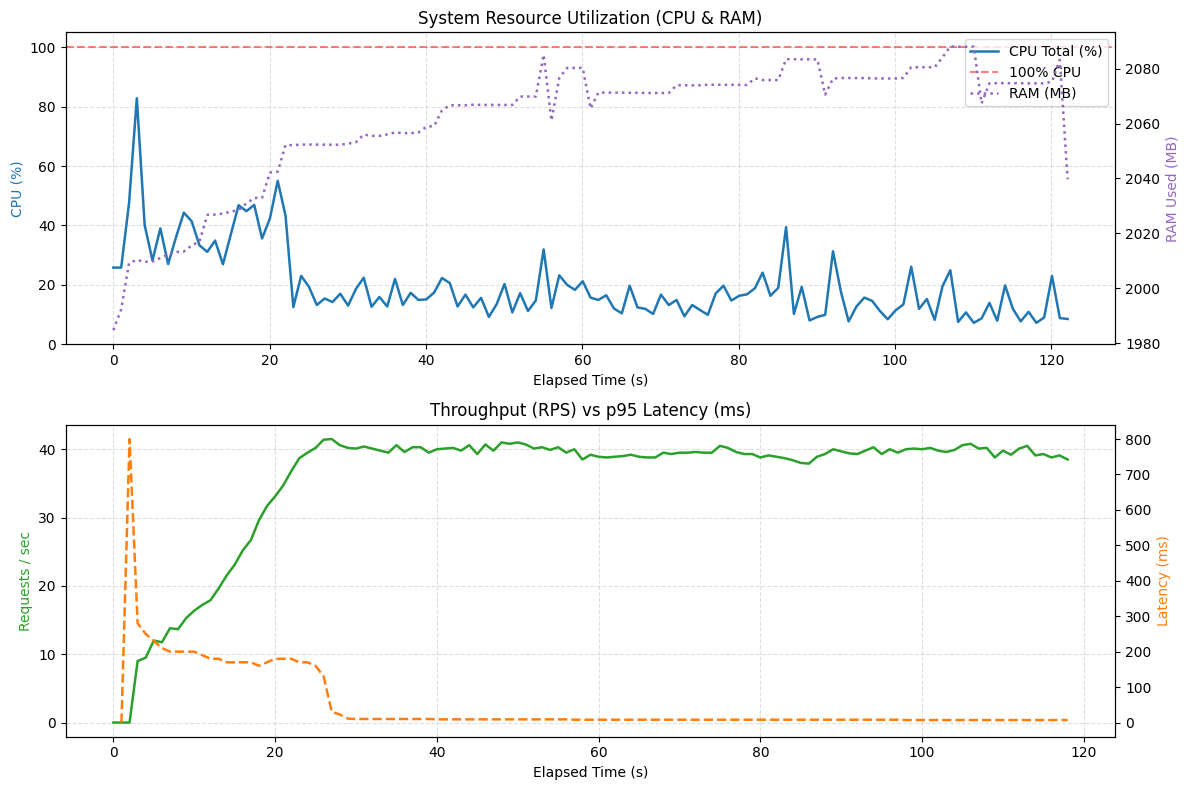

Report chart saved to /kaggle/working/kaggle_load_benchmark.png


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

metrics_df = pd.DataFrame(system_metrics)
if not metrics_df.empty:
    metrics_df["elapsed_sec"] = metrics_df["timestamp"] - metrics_df["timestamp"].min()

stats_file = "/kaggle/working/kaggle_load_results_stats.csv"
if os.path.exists(stats_file):
    stats_df = pd.read_csv(stats_file)
    display_cols = [c for c in ["Type", "Name", "Request Count", "Failure Count", "Median Response Time", "95%", "Requests/s"] if c in stats_df.columns]
    print("Locust Endpoint Statistics:")
    display(stats_df[display_cols])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# CPU and RAM usage
if not metrics_df.empty:
    ax1.plot(metrics_df["elapsed_sec"], metrics_df["cpu_total_pct"], label="CPU Total (%)", color="#1f77b4", linewidth=1.8)
    ax1.axhline(100, color="red", linestyle="--", alpha=0.5, label="100% CPU")
    ax1.set_title("System Resource Utilization (CPU & RAM)")
    ax1.set_xlabel("Elapsed Time (s)")
    ax1.set_ylabel("CPU (%)", color="#1f77b4")
    ax1.set_ylim(0, 105)
    ax1.grid(True, linestyle="--", alpha=0.4)

    ax1_ram = ax1.twinx()
    ax1_ram.plot(metrics_df["elapsed_sec"], metrics_df["ram_used_mb"], label="RAM (MB)", color="#9467bd", linestyle=":", linewidth=1.8)
    ax1_ram.set_ylabel("RAM Used (MB)", color="#9467bd")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_ram.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Throughput vs p95 Latency
history_file = "/kaggle/working/kaggle_load_results_stats_history.csv"
if os.path.exists(history_file) and os.path.getsize(history_file) > 0:
    hist_df = pd.read_csv(history_file)

    if "Name" in hist_df.columns and "Aggregated" in hist_df["Name"].values:
        hist_df = hist_df[hist_df["Name"] == "Aggregated"].copy()

    time_col = "Timestamp" if "Timestamp" in hist_df.columns else hist_df.columns[0]
    hist_df["elapsed_sec"] = hist_df[time_col] - hist_df[time_col].min()

    rps_col = next((c for c in ["Requests/s", "Total Requests/s", "Current RPS", "Requests/sec"] if c in hist_df.columns), None)
    p95_col = next((c for c in ["95%", "95%tile", "Total 95%"] if c in hist_df.columns), None)

    if rps_col:
        ax2.plot(hist_df["elapsed_sec"], hist_df[rps_col], color="#2ca02c", label=f"RPS ({rps_col})", linewidth=1.8)
        ax2.set_ylabel("Requests / sec", color="#2ca02c")

    if p95_col:
        ax2_twin = ax2.twinx()
        ax2_twin.plot(hist_df["elapsed_sec"], hist_df[p95_col], color="#ff7f0e", linestyle="--", label="p95 Latency (ms)", linewidth=1.8)
        ax2_twin.set_ylabel("Latency (ms)", color="#ff7f0e")

    ax2.set_title("Throughput (RPS) vs p95 Latency (ms)")
    ax2.set_xlabel("Elapsed Time (s)")
    ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("/kaggle/working/kaggle_load_benchmark.png", dpi=150)
plt.show()
print("Report chart saved to /kaggle/working/kaggle_load_benchmark.png")